Plotting the processed data to visualize the steps.

Author: Tayler LaSharr

Date: September 2024

Read in libraries and the data we care about.

In [61]:
import rasterio
from rasterio.enums import Resampling
import numpy as np
import matplotlib.pyplot as plt
import os
import re
from datetime import datetime

## define the directories for AZ and WY
base_dir = r'H:\My Drive\DroughtSurfing'
locations = ['WY', 'AZ', 'UT']
# locations = ['WY', 'UT']

## define file paths for the exported GeoTIFFs within each directory
ndvi_file_patterns = {
    'modis_ndvi': 'modis_ndvi.tif',  # single file
    'modis_ndvi_filtered': 'modis_ndvi_filtered.tif',  # single file
    'modis_ndvi_corrected': 'modis_ndvi_corrected_{}.tif',  # yearly files
    'smoothed_ndvi': 'smoothed_ndvi_{}.tif'  # yearly files
}
## get the years
years = range(2015, 2023 + 1)  # Modify this range based on your data


Functions for plotting.

In [62]:
## Function to extract dates from the band names (assuming format: YYYY_MM_DD_NDVI)
def extract_dates(band_names):
    dates = []
    for name in band_names:
        ## Extract the date part from the name using regex
        match = re.search(r'(\d{4}_\d{2}_\d{2})', name)
        if match:
            date_str = match.group(1)
            ## Convert string to datetime object
            date_obj = datetime.strptime(date_str, '%Y_%m_%d')
            dates.append(date_obj)
    return dates

## Function to read NDVI data and calculate the mean NDVI over time
def read_single_ndvi_file(ndvi_path):
    with rasterio.open(ndvi_path) as src:
        ndvi_data = src.read()  # Read all bands (layers) in the file
        band_names = src.descriptions  # Get band descriptions (dates)
        dates = extract_dates(band_names)
    return dates, ndvi_data

## Function to resample a raster to a target shape
def resample_raster(src, target_shape):
    """Resample the raster to match the target shape."""
    data = src.read(
        out_shape=(src.count, target_shape[0], target_shape[1]),
        resampling=Resampling.bilinear  # or Resampling.nearest
    )
    return data

## function to calculate mean NDVI over time for each stack
def calculate_mean_ndvi(ndvi_stack):
    return [np.nanmedian(ndvi_stack[i, :, :]) for i in range(ndvi_stack.shape[0])]

## function to get common bounding box (extent) from a list of rasters
def get_common_extent(rasters):
    """Get the common bounding box (extent) from a list of rasters."""
    extents = []
    for raster in rasters:
        with rasterio.open(raster) as src:
            extents.append(src.bounds)
    
    ## calculate the intersection of all bounding boxes (common extent)
    min_x = max([extent.left for extent in extents])
    max_x = min([extent.right for extent in extents])
    min_y = max([extent.bottom for extent in extents])
    max_y = min([extent.top for extent in extents])
    return rasterio.coords.BoundingBox(min_x, min_y, max_x, max_y)


## function to read and stack NDVI that was saved yearly, with resampling
def read_and_stack_ndvi_data(tiff_dir, file_pattern, years, target_shape=None):
    stacked_ndvi = []
    dates = []

    for year in years:
        file_name = file_pattern.format(year)
        ndvi_path = os.path.join(tiff_dir, file_name)

        if os.path.exists(ndvi_path):
            with rasterio.open(ndvi_path) as src:
                ndvi_data = src.read()  # read all bands (layers) in the file

                ## resample to match the target shape, if necessary
                if target_shape is not None and (src.height != target_shape[0] or src.width != target_shape[1]):
                    print(f"Resampling {file_name} from {src.shape} to {target_shape}")
                    ndvi_data = resample_raster(src, target_shape)
                else:
                    if target_shape is None:
                        target_shape = (src.height, src.width)

                stacked_ndvi.append(ndvi_data)

                band_names = src.descriptions  # get band descriptions (dates)
                dates.extend(extract_dates(band_names))

    ## stack all the NDVI arrays along the first dimension (time)
    if stacked_ndvi:
        stacked_ndvi = np.concatenate(stacked_ndvi, axis=0)

    return dates, stacked_ndvi, target_shape


Plot the figures (unscaled data).

C:\Users\tlasharr\AppData\Local\Temp\ipykernel_19936\2862811557.py:33: RuntimeWarning: All-NaN slice encountered
  return [np.nanmedian(ndvi_stack[i, :, :]) for i in range(ndvi_stack.shape[0])]


Resampling modis_ndvi_corrected_2017.tif from (752, 958) to (751, 1677)
Resampling smoothed_ndvi_2015.tif from (752, 958) to (751, 1677)
Resampling smoothed_ndvi_2016.tif from (752, 958) to (751, 1677)
Resampling smoothed_ndvi_2017.tif from (752, 958) to (751, 1677)
Resampling smoothed_ndvi_2018.tif from (752, 958) to (751, 1677)


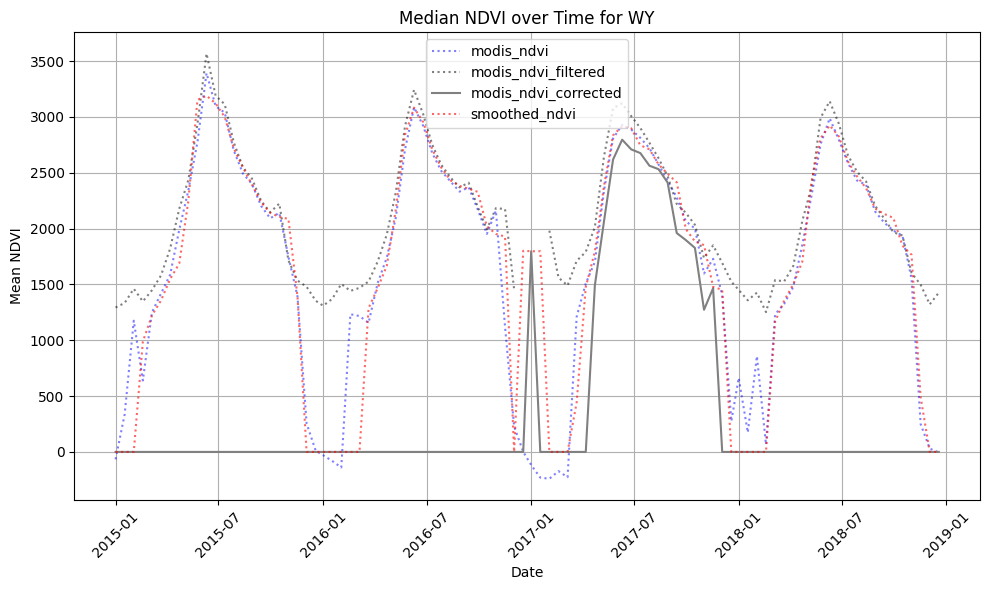

Resampling smoothed_ndvi_2015.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2016.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2017.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2018.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2019.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2020.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2021.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2022.tif from (29, 54) to (28, 75)
Resampling smoothed_ndvi_2023.tif from (29, 54) to (28, 75)


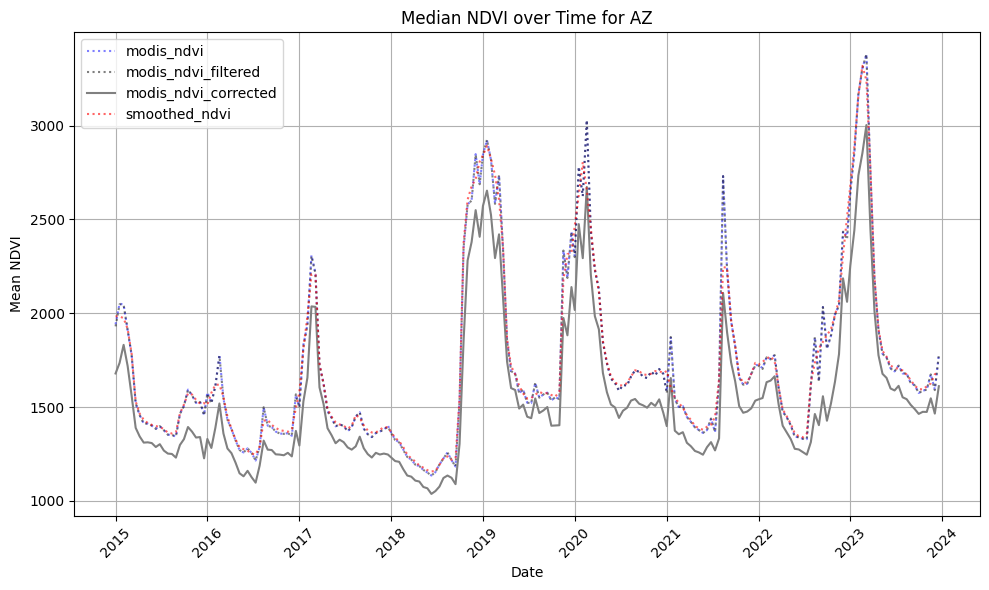

Resampling smoothed_ndvi_2015.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2016.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2017.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2018.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2019.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2020.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2021.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2022.tif from (84, 174) to (85, 237)
Resampling smoothed_ndvi_2023.tif from (84, 174) to (85, 237)


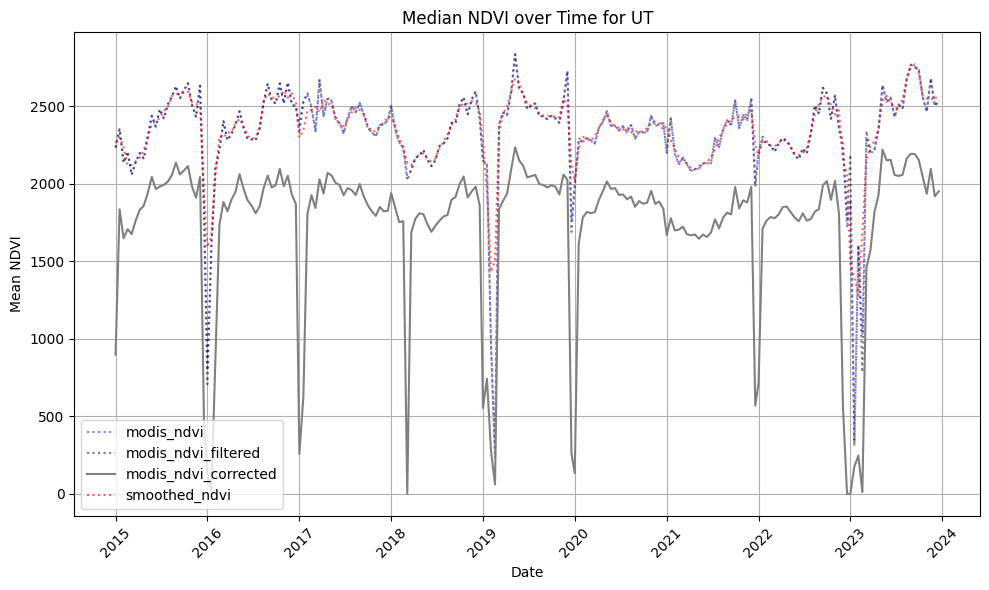

In [63]:
## Function to plot NDVI over time
def plot_ndvi_over_time(locations, file_patterns, years, base_dir):
    for location in locations:
        plt.figure(figsize=(10, 6))
        tiff_dir = os.path.join(base_dir, location)

        # Define colors and line styles for different NDVI products
        styles = [':', ':', '-', ':']
        colors = ['blue', 'black', 'gray', 'red']
        alphas = [0.5, 0.5, 1, .6]

        target_shape = None  # To store the target shape for resampling

        for i, (label, file_pattern) in enumerate(file_patterns.items()):
            if 'corrected' in label or 'smoothed' in label:
                # For 'modis_ndvi_corrected' and 'smoothed_ndvi', stack yearly files
                dates, stacked_ndvi, target_shape = read_and_stack_ndvi_data(tiff_dir, file_pattern, years, target_shape)
            else:
                # For 'modis_ndvi' and 'modis_ndvi_filtered', read a single .tif file
                ndvi_path = os.path.join(tiff_dir, file_pattern)
                dates, stacked_ndvi = read_single_ndvi_file(ndvi_path)

            # Calculate mean NDVI for each time step
            mean_ndvi = calculate_mean_ndvi(stacked_ndvi)

            # Plot NDVI for each product
            plt.plot(dates, mean_ndvi, label=label, linestyle=styles[i], color=colors[i], alpha=alphas[i])

        # Add labels, title, and grid for each location
        plt.title(f'Median NDVI over Time for {location}')
        plt.xlabel('Date')
        plt.ylabel('Mean NDVI')
        plt.legend(loc='best')
        plt.grid(True)
        plt.xticks(rotation=45)
        plt.tight_layout()

        # Show each plot separately
        plt.show()

# Call the function to plot the NDVI over time for each location
plot_ndvi_over_time(locations, ndvi_file_patterns, years, base_dir)